## Imports

In [62]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler

## Data Preprocessing & Cleaning

### Data Reading

In [39]:
df = pd.read_csv('../data/heart_disease.csv')
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


In [40]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    float64
 1   sex       303 non-null    float64
 2   cp        303 non-null    float64
 3   trestbps  303 non-null    float64
 4   chol      303 non-null    float64
 5   fbs       303 non-null    float64
 6   restecg   303 non-null    float64
 7   thalach   303 non-null    float64
 8   exang     303 non-null    float64
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    float64
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  num       303 non-null    int64  
dtypes: float64(13), int64(1)
memory usage: 33.3 KB


### Data Inspection

In [41]:
df.isna().sum()

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
num         0
dtype: int64

In [42]:
cols_with_missing_values = df.columns[df.isna().any()].tolist()
cols_with_missing_values

['ca', 'thal']

In [43]:
# ca: number of major vessels (0-3) colored by flourosopy
# thal: 3 = normal; 6 = fixed defect; 7 = reversable defect

for col in cols_with_missing_values:
    print(f"Column: {col}")
    print(f"Value Counts: {df[col].value_counts()}")
    print(f"Mode: {df[col].mode()[0]}")
    print("-" * 40)

Column: ca
Value Counts: ca
0.0    176
1.0     65
2.0     38
3.0     20
Name: count, dtype: int64
Mode: 0.0
----------------------------------------
Column: thal
Value Counts: thal
3.0    166
7.0    117
6.0     18
Name: count, dtype: int64
Mode: 3.0
----------------------------------------


### Data Splitting

In [44]:
X = df.drop(columns="num")
y = (df["num"] > 0).astype(int)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

### Imputing NA Values

In [45]:
# Fill the 'ca' and 'thal' missing values with the mode since they are categorical variables.
for col in cols_with_missing_values:
    mode_value = X_train[col].mode()[0]

    X_train[col] = X_train[col].fillna(mode_value)
    X_test[col] = X_test[col].fillna(mode_value)

In [46]:
X_train.isna().any().sum() 

np.int64(0)

In [47]:
X_test.isna().any().sum()

np.int64(0)

### Data Encoding

In [48]:
categorical_cols = ["cp", "restecg", "slope", "thal", "ca", "sex", "fbs", "exang"]

In [49]:
for col in categorical_cols:
    print(f"Column: {col}")
    print(f"Value Counts: {df[col].value_counts()}")
    print("-" * 40)

Column: cp
Value Counts: cp
4.0    144
3.0     86
2.0     50
1.0     23
Name: count, dtype: int64
----------------------------------------
Column: restecg
Value Counts: restecg
0.0    151
2.0    148
1.0      4
Name: count, dtype: int64
----------------------------------------
Column: slope
Value Counts: slope
1.0    142
2.0    140
3.0     21
Name: count, dtype: int64
----------------------------------------
Column: thal
Value Counts: thal
3.0    166
7.0    117
6.0     18
Name: count, dtype: int64
----------------------------------------
Column: ca
Value Counts: ca
0.0    176
1.0     65
2.0     38
3.0     20
Name: count, dtype: int64
----------------------------------------
Column: sex
Value Counts: sex
1.0    206
0.0     97
Name: count, dtype: int64
----------------------------------------
Column: fbs
Value Counts: fbs
0.0    258
1.0     45
Name: count, dtype: int64
----------------------------------------
Column: exang
Value Counts: exang
0.0    204
1.0     99
Name: count, dtype: int6

In [51]:
# Keep binary columns (sex, fbs, exang) unchanged and keep ca as a numerical count. One-hot encode the remaining categorical columns (cp, restecg, slope, thal).
to_encode = ["cp", "restecg", "slope", "thal"]

encoder = OneHotEncoder(drop="first",handle_unknown="ignore",sparse_output=False)

X_train_encoded = encoder.fit_transform(X_train[to_encode])
X_test_encoded = encoder.transform(X_test[to_encode])

In [54]:
X_train_encoded

array([[0., 0., 1., ..., 0., 0., 1.],
       [1., 0., 0., ..., 0., 0., 0.],
       [1., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 1., ..., 0., 0., 1.],
       [0., 1., 0., ..., 0., 0., 1.],
       [1., 0., 0., ..., 1., 0., 1.]], shape=(242, 9))

In [59]:
encoded_cols = encoder.get_feature_names_out(to_encode)

for data, encoded_data in [(X_train, X_train_encoded),(X_test, X_test_encoded)]:
    data.drop(columns=to_encode, inplace=True)
    data[encoded_cols] = encoded_data

In [60]:
X_train.head()

,age,sex,trestbps,chol,fbs,thalach,exang,oldpeak,ca,cp_2.0,cp_3.0,cp_4.0,restecg_1.0,restecg_2.0,slope_2.0,slope_3.0,thal_6.0,thal_7.0
180,48.0,1.0,124.0,274.0,0.0,166.0,0.0,0.5,0.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0
208,55.0,1.0,130.0,262.0,0.0,155.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
167,54.0,0.0,132.0,288.0,1.0,159.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
105,54.0,1.0,108.0,309.0,0.0,156.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
297,57.0,0.0,140.0,241.0,0.0,123.0,1.0,0.2,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0


### Data Scaling

In [61]:
numerical_cols = ["age", "trestbps", "chol", "thalach", "oldpeak", "ca"]

scaler = StandardScaler()

X_train[numerical_cols] = scaler.fit_transform(X_train[numerical_cols])
X_test[numerical_cols] = scaler.transform(X_test[numerical_cols])

X_train.head()

,age,sex,trestbps,chol,fbs,thalach,exang,oldpeak,ca,cp_2.0,cp_3.0,cp_4.0,restecg_1.0,restecg_2.0,slope_2.0,slope_3.0,thal_6.0,thal_7.0
180,-0.729485,1.0,-0.395692,0.458139,0.0,0.708371,0.0,-0.445445,-0.689715,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0
208,0.050166,1.0,-0.054513,0.230598,0.0,0.222495,0.0,-0.891627,-0.689715,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
167,-0.061212,0.0,0.059213,0.723605,1.0,0.399178,1.0,-0.891627,0.445734,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
105,-0.061212,1.0,-1.305501,1.121803,0.0,0.266666,0.0,-0.891627,-0.689715,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
297,0.272924,0.0,0.514117,-0.167601,0.0,-1.190962,1.0,-0.713154,-0.689715,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0


## Exploratory Data Analysis

In [63]:
EDA_df = X.loc[X_train.index].copy()
EDA_df["target"] = y_train

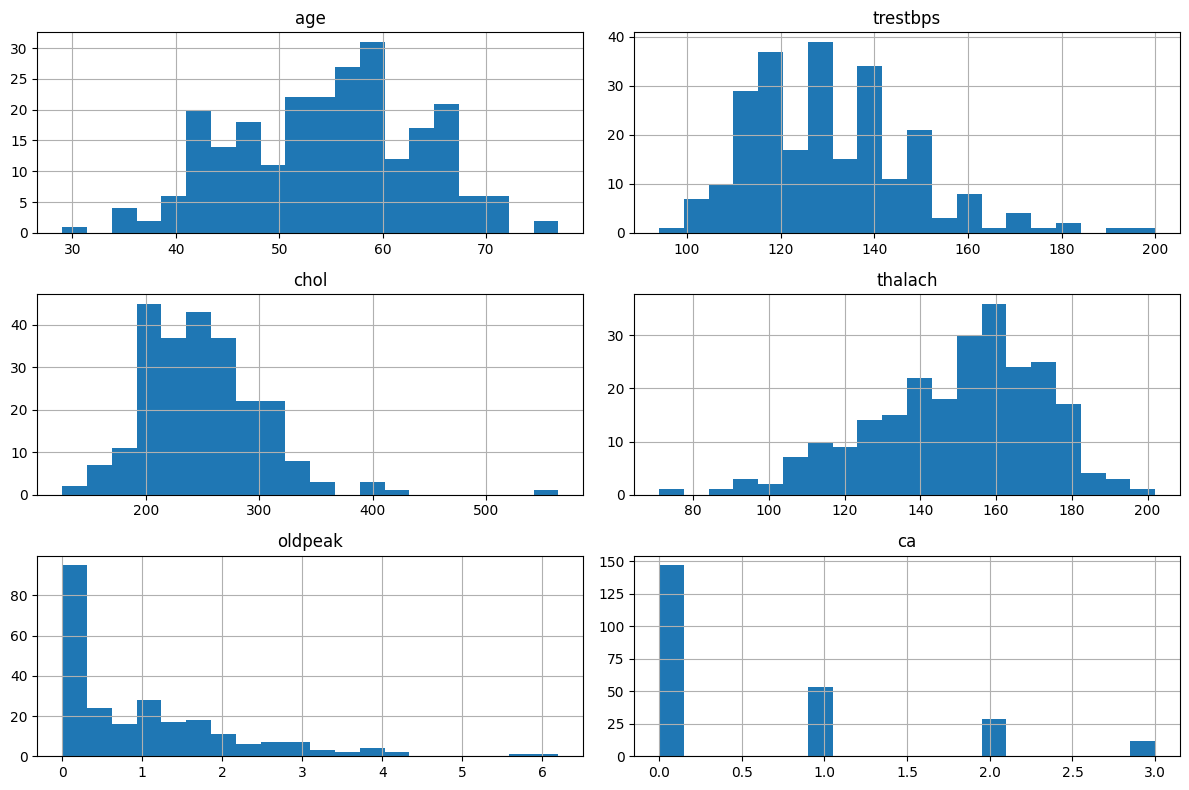

In [64]:
# Visualize the distributions of the numerical features in the training set
EDA_df[numerical_cols].hist(bins=20, figsize=(12, 8))
plt.tight_layout()
plt.show()

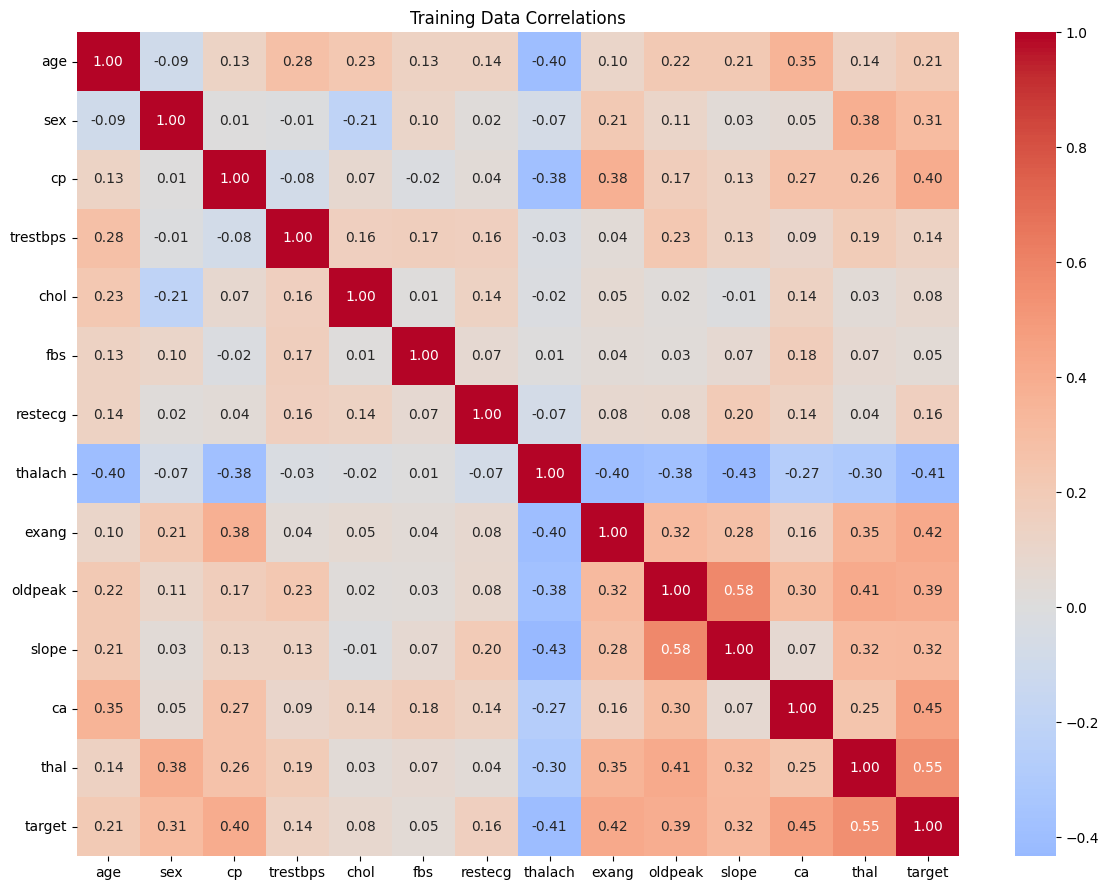

In [65]:
# Visualize the correlations between the features in the training set
plt.figure(figsize=(12, 9))
sns.heatmap(EDA_df.corr(),annot=True,fmt=".2f",cmap="coolwarm",center=0)
plt.title("Training Data Correlations")
plt.tight_layout()
plt.show()

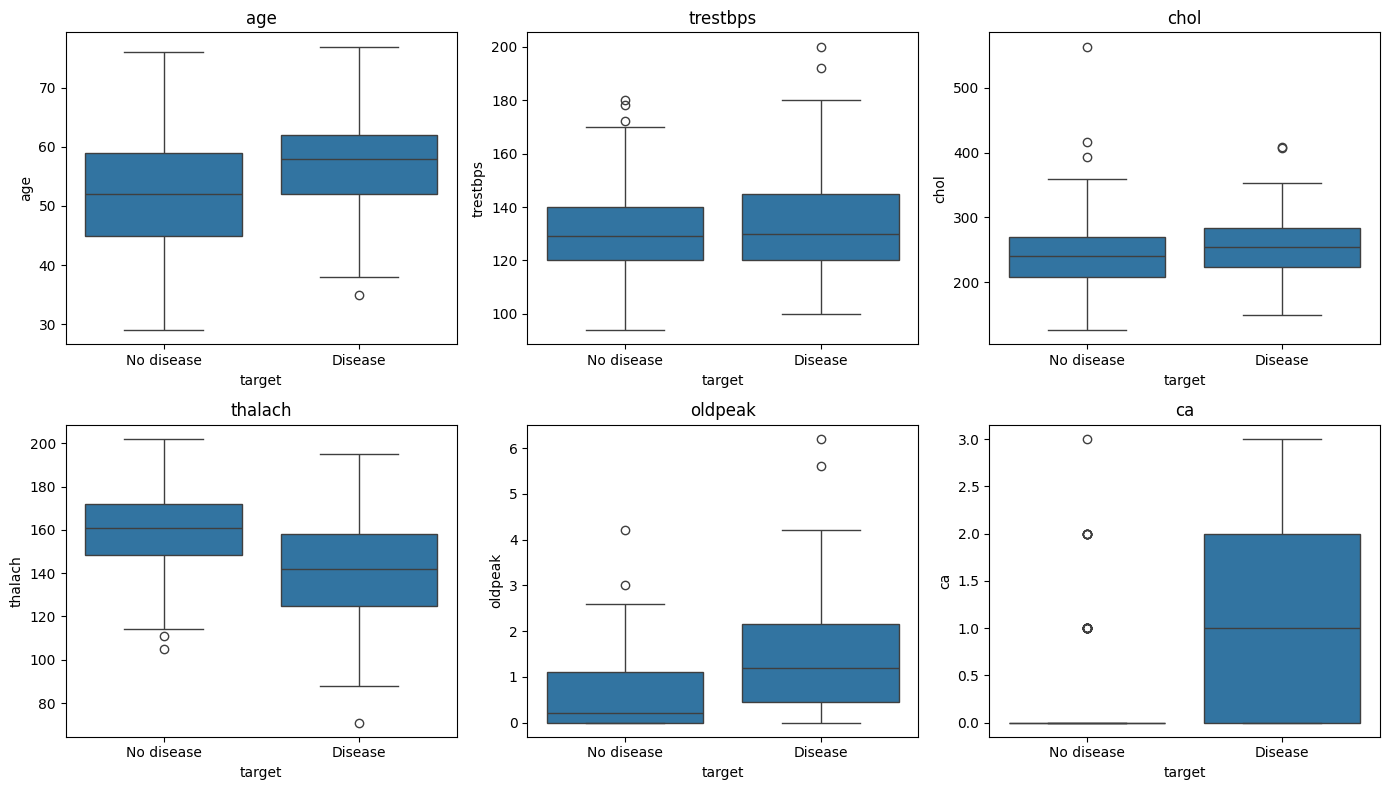

In [66]:
# Visualize the distributions of the numerical features in the training set, grouped by the target variable
fig, axes = plt.subplots(2, 3, figsize=(14, 8))

for col, ax in zip(numerical_cols, axes.flat):
    sns.boxplot(data=EDA_df, x="target", y=col, ax=ax)
    ax.set_title(col)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["No disease", "Disease"])

plt.tight_layout()
plt.show()

## Saving the Processed Data

In [67]:
X_train.to_csv("../data/X_train_processed.csv", index=False)
X_test.to_csv("../data/X_test_processed.csv", index=False)

y_train.to_csv("../data/y_train.csv", index=False)
y_test.to_csv("../data/y_test.csv", index=False)